# Route B, Pipeline 2: Working Investigation with XGBoost

**Team:** Jose De Leon, Rylan Van Komen, Nick Austin
**Checkpoint:** Evidence and Interpretation (due November 19, 2026)

**Question:** Do NFL Combine measurements predict how much a rookie *starts* early in his NFL career, and do the Combine **tracking** (sensor) data add anything beyond the traditional stopwatch/tape-measure results?

**What changed from Pipeline 1 (`kaggle_pipeline.ipynb`):**

| | Pipeline 1 | Pipeline 2 (this notebook) |
|---|---|---|
| Model | `HistGradientBoostingRegressor` | `XGBRegressor` / `XGBClassifier`, shallower and more regularized |
| Outcome | raw `career_games_started` (2023 class has had 3 seasons, 2025 class only 1) | **start rate** = games started / games possible since the player's draft year |
| Missing combine drills | median imputation | left as `NaN` (XGBoost learns a default split direction, so "did not run the drill" is kept as information) |
| Features | 13 traditional combine columns + draft year | traditional columns **+ 19 player-level features engineered from `combine_tracking.csv`** (plus NGS scores and draft capital as reference sets) |
| Validation | one 75/25 holdout + 5-fold CV, no baseline CV | 5x5 repeated K-fold with **identical folds for every feature set and both baselines**, the original 75/25 holdout for a direct bridge to Pipeline 1, and leave-one-draft-class-out |

The notebook only reads from `data/`. Set `SAVE_OUTPUTS = True` in the config cell to also write the metric tables, figures and predictions to `outputs/`.

## 0. Setup

Requires `xgboost` in addition to the packages in `pyproject.toml`. Without changing the project's environment you can run the whole notebook with:

```bash
uv run --with xgboost --with nbconvert jupyter nbconvert --to notebook --execute --inplace working_investigation_python.ipynb
```

(On macOS, XGBoost needs the OpenMP runtime: `brew install libomp` if the import fails.)

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost
from xgboost import XGBRegressor, XGBClassifier
from sklearn.model_selection import RepeatedKFold, RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| matplotlib", matplotlib.__version__)

pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1 | xgboost 3.4.1 | matplotlib 3.11.2


### Config (edit these)

In [2]:
DATA_DIR = "data"
RANDOM_STATE = 307            # same seed as Pipeline 1, so the 75/25 holdout is the identical split
N_SPLITS, N_REPEATS = 5, 5    # repeated K-fold: 25 train/validation splits shared by every model
GAMES_PER_SEASON = 17
LAST_SEASON = 2025            # career data run through the 2025 season (2023 class max = 51 games = 3 x 17)
STARTER_THRESHOLD = 0.5       # "regular starter" = started at least half of possible games
SAVE_OUTPUTS = False          # True -> write CSVs/PNGs to OUTPUT_DIR
OUTPUT_DIR = "outputs"

XGB_PARAMS = dict(
    n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
    tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE,
)

# chart colors (validated categorical order) and neutral ink
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "gray": "#8a8984", "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": C["ink2"],
                     "axes.labelcolor": C["ink"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
                     "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10})

if SAVE_OUTPUTS:
    import os
    os.makedirs(OUTPUT_DIR, exist_ok=True)


def save(obj, name):
    """Write a DataFrame (csv) or Figure (png) to OUTPUT_DIR when SAVE_OUTPUTS is on."""
    if not SAVE_OUTPUTS:
        return
    path = f"{OUTPUT_DIR}/{name}"
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(path, index=False)
    else:
        obj.savefig(path, bbox_inches="tight", dpi=150)
    print("saved", path)

## 1. Load the raw competition files

In [3]:
combine = pd.read_csv(f"{DATA_DIR}/combine_results.csv")
career = pd.read_csv(f"{DATA_DIR}/player_career_successes.csv")
players = pd.read_csv(f"{DATA_DIR}/players.csv")
tracking = pd.read_csv(
    f"{DATA_DIR}/combine_tracking.csv",
    usecols=["nfl_id", "event_id", "entity_type", "time", "drill_type", "drill_name", "attempt", "x", "y", "s", "a", "dis"],
)
for name, df in [("combine_results", combine), ("player_career_successes", career),
                 ("players", players), ("combine_tracking", tracking)]:
    print(f"{name:<25} {df.shape[0]:>8,} rows  {df.shape[1]:>3} cols  {df['nfl_id'].nunique():>4} players")

combine_results                510 rows   18 cols   510 players
player_career_successes        510 rows    9 cols   510 players
players                        510 rows   10 cols   510 players
combine_tracking           463,189 rows   12 cols   510 players


## 2. Outcome: fix the career-exposure problem

Raw `career_games_started` mixes three draft classes with different amounts of time in the league. A 2025 rookie can have at most 17 starts, a 2023 rookie 51. Pipeline 1 tried to absorb this with `draft_year` as a feature. Here the target itself is put on a common scale:

`start_rate = career_games_started / (17 x seasons since the draft)`, clipped to [0, 1].

A secondary binary target, `regular_starter`, flags players who started at least half of the games they could have.

In [4]:
outcome = career.merge(players[["nfl_id", "draft_year"]], on="nfl_id", how="left", validate="one_to_one")
outcome["seasons_available"] = LAST_SEASON - outcome["draft_year"] + 1
outcome["games_possible"] = GAMES_PER_SEASON * outcome["seasons_available"]
outcome["start_rate"] = (outcome["career_games_started"] / outcome["games_possible"]).clip(0, 1)
outcome["regular_starter"] = (outcome["start_rate"] >= STARTER_THRESHOLD).astype(int)

exposure_table = (outcome.groupby("draft_year")
                  .agg(players=("nfl_id", "size"), seasons=("seasons_available", "first"),
                       max_games_started=("career_games_started", "max"),
                       mean_games_started=("career_games_started", "mean"),
                       mean_start_rate=("start_rate", "mean"),
                       share_zero_starts=("career_games_started", lambda s: (s == 0).mean()),
                       share_regular_starter=("regular_starter", "mean"))
                  .round(3).reset_index())
exposure_table

,draft_year,players,seasons,max_games_started,mean_games_started,mean_start_rate,share_zero_starts,share_regular_starter
0,2023,160,3,50,12.475,0.245,0.350,0.225
1,2024,177,2,34,8.000,0.235,0.362,0.220
2,2025,173,1,17,3.428,0.202,0.509,0.162


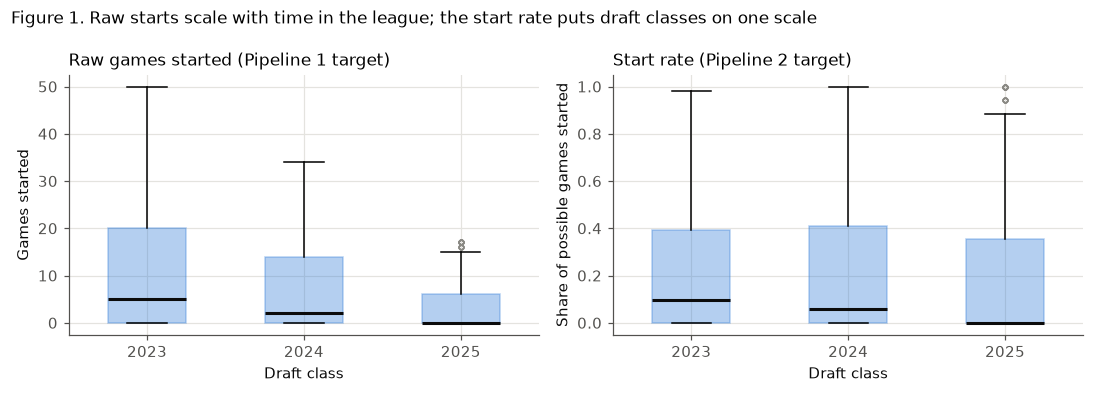

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
years = sorted(outcome["draft_year"].unique())
for ax, col, title in [(axes[0], "career_games_started", "Raw games started (Pipeline 1 target)"),
                       (axes[1], "start_rate", "Start rate (Pipeline 2 target)")]:
    data = [outcome.loc[outcome["draft_year"] == y, col] for y in years]
    bp = ax.boxplot(data, tick_labels=[str(y) for y in years], widths=0.5, patch_artist=True,
                    medianprops=dict(color=C["ink"], linewidth=2), flierprops=dict(markersize=3, markeredgecolor=C["gray"]))
    for patch in bp["boxes"]:
        patch.set(facecolor=C["blue"], alpha=0.35, edgecolor=C["blue"])
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Draft class")
axes[0].set_ylabel("Games started")
axes[1].set_ylabel("Share of possible games started")
fig.suptitle("Figure 1. Raw starts scale with time in the league; the start rate puts draft classes on one scale",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "fig1_exposure.png")
plt.show()

## 3. Feature engineering from `combine_tracking.csv`

The tracking file has ~431k player frames at 10 Hz (ball frames are dropped). Each `(nfl_id, event_id)` is one attempt at one drill. Features are computed per attempt, then collapsed to **one row per player** (best attempt), so no player contributes more than one observation.

* **40-yard dash (418 players):** tracked 10- and 40-yard times from the first tracked frame, peak speed, peak acceleration, time to peak speed, and distance needed to reach 90% of peak speed.
* **Short shuttle (170) and three-cone (160):** peak speed, peak acceleration, peak deceleration, and time spent moving.
* **Position skill drills (all 510 players):** every player ran position-group drills. Raw speeds are not comparable across drills, so each player's peak speed and peak acceleration are z-scored *within each drill* and averaged across the drills he ran.

In [6]:
t0 = time.time()
trk = tracking[tracking["entity_type"] == "PLAYER"].copy()
trk["t"] = pd.to_datetime(trk["time"])
trk = trk.sort_values(["nfl_id", "event_id", "t"]).reset_index(drop=True)
key = ["nfl_id", "event_id"]
g = trk.groupby(key, sort=False)
trk["sec"] = (trk["t"] - g["t"].transform("min")).dt.total_seconds()
trk["dt"] = g["sec"].diff()
trk["ds_dt"] = g["s"].diff() / trk["dt"]                    # signed change in speed -> deceleration
x0, y0 = g["x"].transform("first"), g["y"].transform("first")
trk["disp"] = np.hypot(trk["x"] - x0, trk["y"] - y0)       # straight-line distance from the attempt's first frame
print(f"{len(trk):,} player frames, {trk.groupby(key).ngroups:,} drill attempts  ({time.time()-t0:.1f}s)")


def first_time_reaching(sub, col, threshold):
    hit = sub.loc[sub[col] >= threshold, "sec"]
    return hit.iloc[0] if len(hit) else np.nan


def forty_attempt(sub):
    peak = sub["s"].max()
    i_peak = sub["s"].idxmax()
    reach90 = sub.loc[sub["s"] >= 0.9 * peak]
    return pd.Series({
        "trk40_time_10yd": first_time_reaching(sub, "disp", 10),
        "trk40_time_40yd": first_time_reaching(sub, "disp", 40),
        "trk40_peak_speed": peak,
        "trk40_peak_accel": sub["a"].max(),
        "trk40_time_to_peak": sub.at[i_peak, "sec"],
        "trk40_dist_to_90pct": reach90["disp"].iloc[0] if len(reach90) else np.nan,
    })


def agility_attempt(sub):
    moving = sub.loc[sub["s"] > 0.5, "sec"]
    return pd.Series({
        "peak_speed": sub["s"].max(),
        "peak_accel": sub["a"].max(),
        "peak_decel": -sub["ds_dt"].min(),
        "moving_time": (moving.iloc[-1] - moving.iloc[0]) if len(moving) > 1 else np.nan,
    })


# 40-yard dash: best (fastest / highest) value across a player's attempts
f40 = trk[trk["drill_name"] == "FORTY_YARD_DASH"].groupby(key).apply(forty_attempt, include_groups=False).reset_index()
best_low = ["trk40_time_10yd", "trk40_time_40yd", "trk40_time_to_peak", "trk40_dist_to_90pct"]
forty_feats = f40.groupby("nfl_id").agg({**{c: "min" for c in best_low},
                                          **{c: "max" for c in ["trk40_peak_speed", "trk40_peak_accel"]}})

# short shuttle and three-cone
agility_parts = []
for drill, prefix in [("SHORT_SHUTTLE", "trkSS"), ("THREE_CONE_DRILL", "trk3C")]:
    a = trk[trk["drill_name"] == drill].groupby(key).apply(agility_attempt, include_groups=False).reset_index()
    a = a.groupby("nfl_id").agg(peak_speed=("peak_speed", "max"), peak_accel=("peak_accel", "max"),
                                peak_decel=("peak_decel", "max"), moving_time=("moving_time", "min"))
    agility_parts.append(a.add_prefix(prefix + "_"))

# position skill drills: within-drill z-scores, averaged per player
skill = trk[trk["drill_type"].str.startswith("SKILL_DRILLS")]
per_drill = skill.groupby(["nfl_id", "drill_name"]).agg(peak_speed=("s", "max"), peak_accel=("a", "max")).reset_index()
per_drill = per_drill[per_drill.groupby("drill_name")["nfl_id"].transform("nunique") >= 10]   # need peers to standardize
for col in ["peak_speed", "peak_accel"]:
    grp = per_drill.groupby("drill_name")[col]
    per_drill[col + "_z"] = (per_drill[col] - grp.transform("mean")) / grp.transform("std")
skill_feats = per_drill.groupby("nfl_id").agg(
    trkSK_speed_z=("peak_speed_z", "mean"), trkSK_accel_z=("peak_accel_z", "mean"),
    trkSK_speed_z_best=("peak_speed_z", "max"), trkSK_top_speed=("peak_speed", "max"),
    trkSK_n_drills=("drill_name", "nunique"))

track_feats = pd.concat([forty_feats, *agility_parts, skill_feats], axis=1).reset_index()
TRACK_FEATURES = [c for c in track_feats.columns if c != "nfl_id"]
print(f"Tracking features built in {time.time()-t0:.1f}s: {len(TRACK_FEATURES)} features for {len(track_feats)} players")
track_feats[TRACK_FEATURES].notna().sum().rename("players_with_value").to_frame().T

431,094 player frames, 6,310 drill attempts  (0.3s)


Tracking features built in 0.8s: 19 features for 510 players


,trk40_time_10yd,trk40_time_40yd,trk40_time_to_peak,trk40_dist_to_90pct,trk40_peak_speed,trk40_peak_accel,trkSS_peak_speed,trkSS_peak_accel,trkSS_peak_decel,trkSS_moving_time,trk3C_peak_speed,trk3C_peak_accel,trk3C_peak_decel,trk3C_moving_time,trkSK_speed_z,trkSK_accel_z,trkSK_speed_z_best,trkSK_top_speed,trkSK_n_drills
players_with_value,418,381,418,418,418,418,170,170,170,170,160,160,160,160,510,510,510,510,510


**Sanity check on the engineered features.** If the tracked 40 time is measuring the same thing as the official stopwatch, the two should correlate strongly. It is not the same number: the tracked clock starts at the first tracked frame, after the player has begun moving.

In [7]:
check = combine[["nfl_id", "forty", "ten_yd_split"]].merge(track_feats, on="nfl_id", how="inner")
sanity = pd.DataFrame({
    "pair": ["tracked 40 time vs official 40", "tracked 10-yd time vs official 10-yd split",
             "tracked 40 peak speed vs official 40", "skill-drill speed z vs official 40"],
    "n": [check[["trk40_time_40yd", "forty"]].dropna().shape[0], check[["trk40_time_10yd", "ten_yd_split"]].dropna().shape[0],
          check[["trk40_peak_speed", "forty"]].dropna().shape[0], check[["trkSK_speed_z", "forty"]].dropna().shape[0]],
    "pearson_r": [check["trk40_time_40yd"].corr(check["forty"]), check["trk40_time_10yd"].corr(check["ten_yd_split"]),
                  check["trk40_peak_speed"].corr(check["forty"]), check["trkSK_speed_z"].corr(check["forty"])],
}).round(3)
sanity

,pair,n,pearson_r
0,tracked 40 time vs official 40,381,0.904
1,tracked 10-yd time vs official 10-yd split,418,0.470
2,tracked 40 peak speed vs official 40,418,-0.978
3,skill-drill speed z vs official 40,424,-0.243


## 4. One modeling table and five nested feature sets

Rows are built in `combine_results.csv` order, exactly like Pipeline 1, so the 75/25 split with `random_state=307` selects the same 128 validation players.

In [8]:
df = (combine.merge(outcome.drop(columns=["draft_year"]), on="nfl_id", how="left", validate="one_to_one")
             .merge(players[["nfl_id", "draft_overall_pick", "draft_round"]], on="nfl_id", how="left", validate="one_to_one")
             .merge(track_feats, on="nfl_id", how="left", validate="one_to_one"))
df["undrafted"] = df["draft_overall_pick"].isna().astype(int)
df["draft_pick_filled"] = df["draft_overall_pick"].fillna(df["draft_overall_pick"].max() + 1)   # undrafted ranked after the last pick
df = pd.concat([df, pd.get_dummies(df["combine_position"], prefix="pos", dtype=int)], axis=1)
POS = [c for c in df.columns if c.startswith("pos_")]

TRADITIONAL = ["combine_height", "combine_weight", "hand_size", "arm_length", "wing_span", "forty", "bench_reps",
               "vertical", "broad_jump", "three_cone", "short_shuttle", "ten_yd_split"]
NGS = ["ngs_athleticism_score", "ngs_college_production_score", "ngs_final_score"]
DRAFT = ["draft_pick_filled", "undrafted"]

FEATURE_SETS = {
    "A. Traditional combine": POS + TRADITIONAL,
    "B. Tracking only": POS + TRACK_FEATURES,
    "C. Traditional + tracking": POS + TRADITIONAL + TRACK_FEATURES,
    "D. C + NGS scores": POS + TRADITIONAL + TRACK_FEATURES + NGS,
    "E. D + draft capital": POS + TRADITIONAL + TRACK_FEATURES + NGS + DRAFT,
}
y_rate = df["start_rate"].to_numpy()
y_starter = df["regular_starter"].to_numpy()
print("Modeling table:", df.shape, "| players:", df["nfl_id"].nunique())
print("Regular starters:", int(y_starter.sum()), f"({y_starter.mean():.1%})")
pd.DataFrame({"feature_set": list(FEATURE_SETS), "n_features": [len(v) for v in FEATURE_SETS.values()]})

Modeling table: (510, 58) | players: 510
Regular starters: 103 (20.2%)


,feature_set,n_features
0,A. Traditional combine,17
1,B. Tracking only,24
2,C. Traditional + tracking,36
3,D. C + NGS scores,39
4,E. D + draft capital,41


## 5. Local validation: 5x5 repeated K-fold, identical folds for every model

Every feature set and both baselines are scored on the **same 25 train/validation splits**, so differences between rows come from the features, not from luck of the split. Two baselines:

* **Global mean:** predict the training-fold mean start rate for everyone.
* **Position mean:** predict the training-fold mean for the player's combine position group (DB, DL, OL, TE, WR). A model has to beat this to show the measurements carry information beyond position.

In [9]:
splits = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE).split(df))


def fold_scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}


def run_cv(predict_fn, name):
    rows, oof = [], np.zeros((N_REPEATS, len(df)))
    for k, (tr, te) in enumerate(splits):
        p = np.clip(predict_fn(tr, te), 0, 1)
        oof[k // N_SPLITS, te] = p
        rows.append({"model": name, "fold": k, **fold_scores(y_rate[te], p)})
    return pd.DataFrame(rows), oof.mean(axis=0)


def global_mean(tr, te):
    return np.full(len(te), y_rate[tr].mean())


def position_mean(tr, te):
    means = pd.Series(y_rate[tr]).groupby(df["combine_position"].iloc[tr].to_numpy()).mean()
    return df["combine_position"].iloc[te].map(means).fillna(y_rate[tr].mean()).to_numpy()


def xgb_reg(features, params=None):
    X = df[features].astype(float)
    def fn(tr, te):
        m = XGBRegressor(objective="reg:squarederror", **(params or XGB_PARAMS))
        m.fit(X.iloc[tr], y_rate[tr])
        return m.predict(X.iloc[te])
    return fn


t0 = time.time()
fold_frames, oof_preds = [], {}
for name, fn in [("Baseline: global mean", global_mean), ("Baseline: position mean", position_mean)] + \
                [(name, xgb_reg(cols)) for name, cols in FEATURE_SETS.items()]:
    folds, oof = run_cv(fn, name)
    fold_frames.append(folds)
    oof_preds[name] = oof
cv_folds = pd.concat(fold_frames, ignore_index=True)
print(f"CV finished in {time.time()-t0:.1f}s")

ref = cv_folds[cv_folds["model"] == "Baseline: position mean"].set_index("fold")["MAE"]
cv_summary = (cv_folds.groupby("model", sort=False)
              .agg(MAE=("MAE", "mean"), MAE_sd=("MAE", "std"), RMSE=("RMSE", "mean"), R2=("R2", "mean"))
              .reset_index())
cv_summary["MAE_vs_position_mean"] = [
    (cv_folds[cv_folds["model"] == m].set_index("fold")["MAE"] - ref).mean() for m in cv_summary["model"]]
cv_summary["folds_beating_position_mean"] = [
    int(((cv_folds[cv_folds["model"] == m].set_index("fold")["MAE"] - ref) < 0).sum()) for m in cv_summary["model"]]
save(cv_summary, "cv_summary_start_rate.csv")
cv_summary.round(4)

CV finished in 25.6s


,model,MAE,MAE_sd,RMSE,R2,MAE_vs_position_mean,folds_beating_position_mean
0,Baseline: global mean,0.2502,0.0159,0.3002,-0.0184,0.0045,7
1,Baseline: position mean,0.2457,0.0174,0.2968,0.0051,0.0000,0
2,A. Traditional combine,0.2352,0.0176,0.2955,0.0100,-0.0106,21
3,B. Tracking only,0.2443,0.0188,0.3059,-0.0597,-0.0015,11
4,C. Traditional + tracking,0.2338,0.0181,0.2955,0.0107,-0.0120,21
5,D. C + NGS scores,0.1780,0.0162,0.2421,0.3332,-0.0677,25
6,E. D + draft capital,0.1471,0.0144,0.2078,0.5089,-0.0986,25


**Paired comparison of the main design change (C vs A).** Same 25 folds, so the per-fold difference isolates what the tracking features add. Folds overlap in training data, so this is a descriptive comparison, not a formal test.

In [10]:
def paired(m1, m2, metric="MAE"):
    a = cv_folds[cv_folds["model"] == m1].set_index("fold")[metric]
    b = cv_folds[cv_folds["model"] == m2].set_index("fold")[metric]
    d = b - a
    return {"comparison": f"{m2}  minus  {m1}", "metric": metric, "mean_diff": d.mean(), "sd_diff": d.std(),
            "folds_where_second_is_better": f"{int((d < 0).sum())}/{len(d)}"}


paired_table = pd.DataFrame([
    paired("A. Traditional combine", "C. Traditional + tracking"),
    paired("A. Traditional combine", "B. Tracking only"),
    paired("C. Traditional + tracking", "D. C + NGS scores"),
    paired("D. C + NGS scores", "E. D + draft capital"),
])
save(paired_table, "cv_paired_differences.csv")
paired_table.round(4)

,comparison,metric,mean_diff,sd_diff,folds_where_second_is_better
0,C. Traditional + tracking minus A. Tradition...,MAE,-0.0014,0.0075,14/25
1,B. Tracking only minus A. Traditional combine,MAE,0.0091,0.0116,6/25
2,D. C + NGS scores minus C. Traditional + tra...,MAE,-0.0557,0.0142,25/25
3,E. D + draft capital minus D. C + NGS scores,MAE,-0.0309,0.0108,25/25


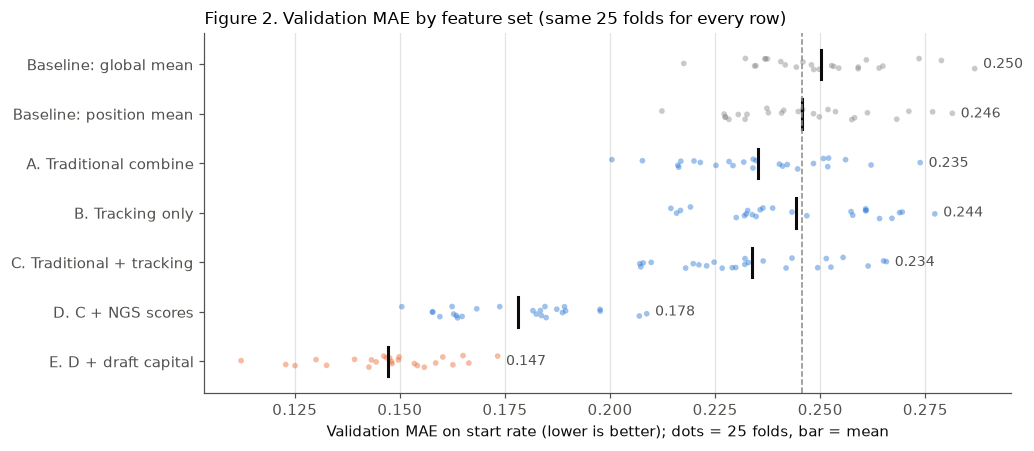

In [11]:
order = list(cv_summary["model"])
colors = [C["gray"], C["gray"], C["blue"], C["blue"], C["blue"], C["blue"], C["orange"]]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for i, (m, col) in enumerate(zip(order, colors)):
    vals = cv_folds.loc[cv_folds["model"] == m, "MAE"].to_numpy()
    jitter = np.random.default_rng(i).uniform(-0.12, 0.12, len(vals))
    ax.scatter(vals, np.full(len(vals), i) + jitter, s=14, color=col, alpha=0.45, edgecolor="none")
    ax.plot([vals.mean()] * 2, [i - 0.3, i + 0.3], color=C["ink"], linewidth=2)
    ax.text(vals.max() + 0.002, i, f"{vals.mean():.3f}", va="center", fontsize=9, color=C["ink2"])
ax.axvline(ref.mean(), color=C["gray"], linestyle="--", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Validation MAE on start rate (lower is better); dots = 25 folds, bar = mean")
ax.set_title("Figure 2. Validation MAE by feature set (same 25 folds for every row)",
             loc="left", fontsize=11)
fig.tight_layout()
save(fig, "fig2_cv_mae_by_feature_set.png")
plt.show()

## 6. Bridge to Pipeline 1: the identical 75/25 holdout

Pipeline 1 reported, on this split, MAE 8.296 for the mean baseline and 8.965 for `HistGradientBoosting` (raw games started). Here XGBoost is run on the **same split and same raw target** first with Pipeline 1's exact features (isolates the model change), then with tracking features added, and finally with the start-rate target (scored back in games so the units match).

In [12]:
P1_FEATURES = ["draft_year"] + POS + TRADITIONAL
idx = np.arange(len(df))
tr_idx, va_idx = train_test_split(idx, test_size=0.25, random_state=RANDOM_STATE)
y_raw = df["career_games_started"].to_numpy(dtype=float)
games_possible = df["games_possible"].to_numpy(dtype=float)
assert len(va_idx) == 128


def holdout_row(name, pred_games):
    pred_games = np.clip(pred_games, 0, None)
    return {"model": name, **fold_scores(y_raw[va_idx], pred_games)}


def fit_predict(features, target):
    X = df[features].astype(float)
    m = XGBRegressor(objective="reg:squarederror", **XGB_PARAMS).fit(X.iloc[tr_idx], target[tr_idx])
    return m.predict(X.iloc[va_idx])


holdout_rows = [
    holdout_row("Mean baseline (raw starts)", np.full(len(va_idx), y_raw[tr_idx].mean())),
    holdout_row("XGB, Pipeline 1 features, raw starts", fit_predict(P1_FEATURES, y_raw)),
    holdout_row("XGB, P1 features + tracking, raw starts", fit_predict(P1_FEATURES + TRACK_FEATURES, y_raw)),
    holdout_row("XGB, set C, start rate x games possible",
                np.clip(fit_predict(FEATURE_SETS["C. Traditional + tracking"], y_rate), 0, 1) * games_possible[va_idx]),
    holdout_row("XGB, set E (+NGS, draft), start rate x games possible",
                np.clip(fit_predict(FEATURE_SETS["E. D + draft capital"], y_rate), 0, 1) * games_possible[va_idx]),
]
holdout = pd.DataFrame(holdout_rows)
try:   # read-only: show Pipeline 1's saved numbers next to these, if the file is present
    p1 = pd.read_csv("validation_metrics.csv").rename(columns={"Model": "model"})
    p1["model"] = "Pipeline 1 file: " + p1["model"]
    holdout = pd.concat([p1[["model", "MAE", "RMSE", "R2"]], holdout], ignore_index=True)
except FileNotFoundError:
    pass
save(holdout, "holdout_bridge_to_pipeline1.csv")
holdout.round(3)

,model,MAE,RMSE,R2
0,Pipeline 1 file: Mean baseline,8.296,10.878,-0.000
1,Pipeline 1 file: HistGradientBoosting,8.965,11.631,-0.143
2,Mean baseline (raw starts),8.296,10.878,-0.000
3,"XGB, Pipeline 1 features, raw starts",8.150,10.869,0.002
4,"XGB, P1 features + tracking, raw starts",8.507,11.395,-0.097
5,"XGB, set C, start rate x games possible",7.991,10.972,-0.017
6,"XGB, set E (+NGS, draft), start rate x games p...",4.658,7.419,0.535


## 7. Does it generalize to a new draft class? Leave-one-draft-class-out

If the competition (or a team) wants to score a **future** class, a random split is optimistic. Here each draft class is held out in turn and the model is trained on the other two.

In [13]:
lodo_rows = []
for year in sorted(df["draft_year"].unique()):
    te = np.where(df["draft_year"] == year)[0]
    tr = np.where(df["draft_year"] != year)[0]
    preds = {"Baseline: global mean": global_mean(tr, te), "Baseline: position mean": position_mean(tr, te)}
    for name in ["A. Traditional combine", "C. Traditional + tracking", "E. D + draft capital"]:
        preds[name] = xgb_reg(FEATURE_SETS[name])(tr, te)
    for name, p in preds.items():
        lodo_rows.append({"held_out_class": year, "n": len(te), "model": name, "MAE": mean_absolute_error(y_rate[te], np.clip(p, 0, 1))})
lodo = pd.DataFrame(lodo_rows).pivot(index="model", columns="held_out_class", values="MAE")
lodo["mean"] = lodo.mean(axis=1)
lodo = lodo.loc[["Baseline: global mean", "Baseline: position mean", "A. Traditional combine",
                 "C. Traditional + tracking", "E. D + draft capital"]]
save(lodo.reset_index(), "leave_one_class_out_mae.csv")
lodo.round(4)

held_out_class,2023,2024,2025,mean
model,,,,
Baseline: global mean,0.2466,0.2475,0.2559,0.2500
Baseline: position mean,0.2440,0.2447,0.2450,0.2446
A. Traditional combine,0.2186,0.2320,0.2519,0.2342
C. Traditional + tracking,0.2246,0.2310,0.2286,0.2281
E. D + draft capital,0.1410,0.1483,0.1613,0.1502


## 8. Secondary framing: classify "regular starter" (ROC-AUC)

MAE on a skewed rate rewards predicting the middle. Ranking players by their chance of becoming a regular starter is closer to how a scout would use the model. Same repeated folds (stratified on the label), same XGBoost settings.

In [14]:
strat_splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS,
                                            random_state=RANDOM_STATE).split(df, y_starter))
pos_codes = df["combine_position"].to_numpy()
auc_rows = []
for k, (tr, te) in enumerate(strat_splits):
    rates = pd.Series(y_starter[tr]).groupby(pos_codes[tr]).mean()
    auc_rows.append({"model": "Baseline: position rate", "fold": k,
                     "AUC": roc_auc_score(y_starter[te], pd.Series(pos_codes[te]).map(rates).fillna(y_starter[tr].mean()))})
    for name, cols in FEATURE_SETS.items():
        X = df[cols].astype(float)
        clf = XGBClassifier(objective="binary:logistic", eval_metric="logloss", **XGB_PARAMS)
        clf.fit(X.iloc[tr], y_starter[tr])
        auc_rows.append({"model": name, "fold": k, "AUC": roc_auc_score(y_starter[te], clf.predict_proba(X.iloc[te])[:, 1])})
auc_folds = pd.DataFrame(auc_rows)
auc_summary = auc_folds.groupby("model", sort=False)["AUC"].agg(["mean", "std", "min", "max"]).reset_index()
save(auc_summary, "cv_auc_regular_starter.csv")
auc_summary.round(3)

,model,mean,std,min,max
0,Baseline: position rate,0.592,0.061,0.428,0.712
1,A. Traditional combine,0.599,0.071,0.449,0.745
2,B. Tracking only,0.606,0.069,0.490,0.718
3,C. Traditional + tracking,0.612,0.055,0.518,0.731
4,D. C + NGS scores,0.838,0.049,0.763,0.941
5,E. D + draft capital,0.903,0.035,0.832,0.976


## 9. Which measurements does the model lean on?

Gain importance from set D (all pre-draft measurements, no draft capital) and set E, each fit on all 510 players. Importance shows what the trees split on, not a causal effect, and correlated features share credit.

In [15]:
def gain_importance(features):
    m = XGBRegressor(objective="reg:squarederror", **XGB_PARAMS).fit(df[features].astype(float), y_rate)
    gain = pd.Series(m.get_booster().get_score(importance_type="gain"), dtype=float).reindex(features).fillna(0)
    return (gain / gain.sum()).sort_values(ascending=False)


imp_D = gain_importance(FEATURE_SETS["D. C + NGS scores"])
imp_E = gain_importance(FEATURE_SETS["E. D + draft capital"])
importance = pd.DataFrame({"feature": imp_D.index, "share_of_gain_set_D": imp_D.values}).merge(
    pd.DataFrame({"feature": imp_E.index, "share_of_gain_set_E": imp_E.values}), on="feature", how="outer")
importance["source"] = np.select(
    [importance["feature"].isin(TRACK_FEATURES), importance["feature"].isin(TRADITIONAL),
     importance["feature"].isin(NGS), importance["feature"].isin(DRAFT)],
    ["tracking", "traditional", "NGS score", "draft"], default="position")
importance = importance.sort_values("share_of_gain_set_D", ascending=False).reset_index(drop=True)
save(importance, "feature_importance_gain.csv")
print("Share of total gain by source:")
print(importance.groupby("source")[["share_of_gain_set_D", "share_of_gain_set_E"]].sum().round(3))
importance.head(15).round(3)

Share of total gain by source:
             share_of_gain_set_D  share_of_gain_set_E
source                                               
NGS score                  0.183                0.114
draft                      0.000                0.252
position                   0.167                0.121
tracking                   0.386                0.310
traditional                0.264                0.204


,feature,share_of_gain_set_D,share_of_gain_set_E,source
0,ngs_final_score,0.117,0.066,NGS score
1,pos_OL,0.110,0.068,position
2,trkSK_n_drills,0.042,0.037,tracking
3,ngs_college_production_score,0.041,0.033,NGS score
4,vertical,0.035,0.017,traditional
5,combine_weight,0.035,0.026,traditional
6,pos_DL,0.033,0.031,position
7,broad_jump,0.029,0.022,traditional
8,trk40_time_40yd,0.028,0.015,tracking
9,trk40_time_10yd,0.027,0.020,tracking


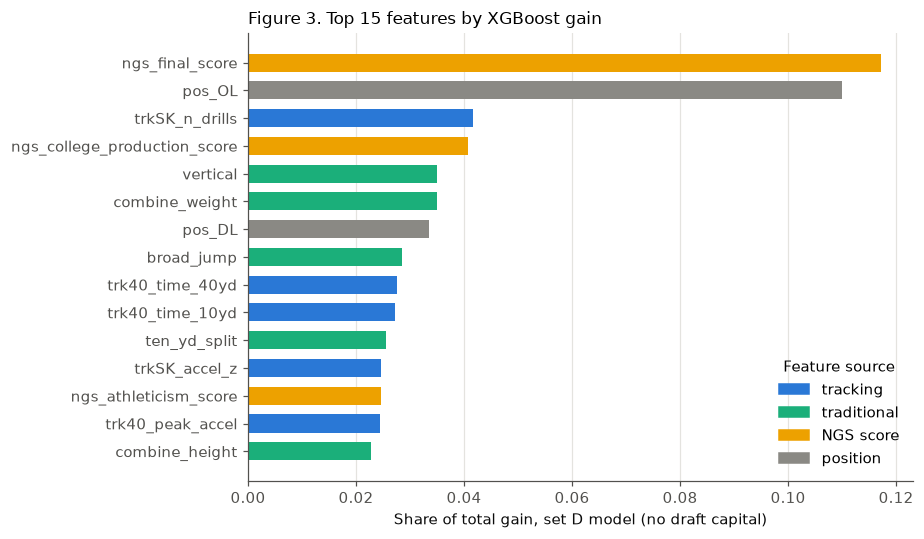

In [16]:
top = importance.head(15).iloc[::-1]
src_color = {"tracking": C["blue"], "traditional": C["aqua"], "NGS score": C["yellow"], "draft": C["orange"], "position": C["gray"]}
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(top["feature"], top["share_of_gain_set_D"], color=[src_color[s] for s in top["source"]], height=0.65)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=s) for s, col in src_color.items() if s in set(top["source"])],
          title="Feature source", frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of total gain, set D model (no draft capital)")
ax.set_title("Figure 3. Top 15 features by XGBoost gain", loc="left", fontsize=11)
fig.tight_layout()
save(fig, "fig3_feature_importance.png")
plt.show()

## 10. Error diagnostic: out-of-fold predictions vs. actual start rate

Out-of-fold predictions averaged over the 5 repeats, so every player is scored by models that never saw him.

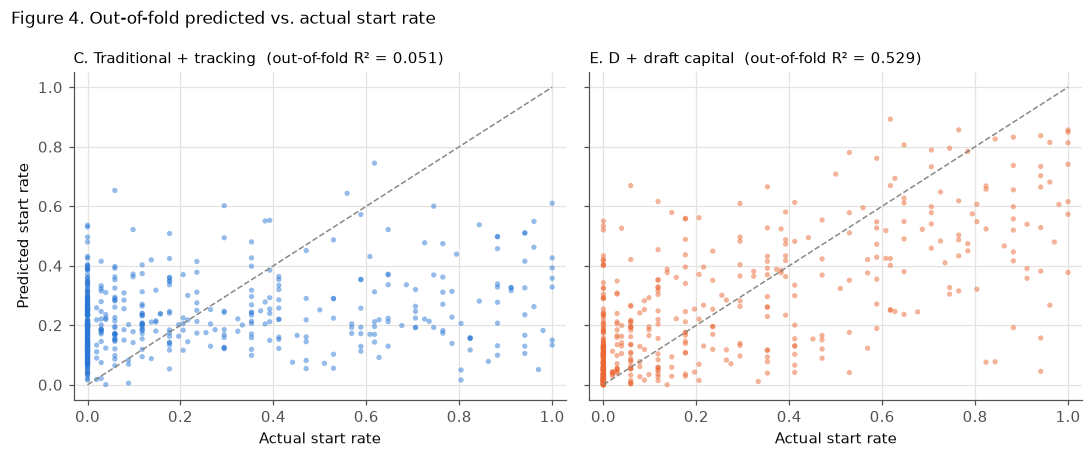

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, name, col in [(axes[0], "C. Traditional + tracking", C["blue"]), (axes[1], "E. D + draft capital", C["orange"])]:
    ax.scatter(y_rate, oof_preds[name], s=12, alpha=0.5, color=col, edgecolor="none")
    ax.plot([0, 1], [0, 1], color=C["gray"], linestyle="--", linewidth=1)
    r2 = r2_score(y_rate, oof_preds[name])
    ax.set_title(f"{name}  (out-of-fold R² = {r2:.3f})", loc="left", fontsize=10)
    ax.set_xlabel("Actual start rate")
    ax.set_xlim(-0.03, 1.03)
axes[0].set_ylabel("Predicted start rate")
fig.suptitle("Figure 4. Out-of-fold predicted vs. actual start rate",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "fig4_oof_pred_vs_actual.png")
plt.show()

In [18]:
err = df[["nfl_id", "combine_position", "draft_year", "draft_round", "start_rate"]].copy()
err["pred_C"] = oof_preds["C. Traditional + tracking"]
err["abs_err_C"] = (err["start_rate"] - err["pred_C"]).abs()
err["zero_starts"] = err["start_rate"].eq(0)
err["drafted"] = err["draft_round"].notna()
err_by_group = pd.concat([
    err.groupby("combine_position")["abs_err_C"].agg(["size", "mean"]).assign(group="position"),
    err.groupby("zero_starts")["abs_err_C"].agg(["size", "mean"]).rename(index={True: "0 starts", False: ">0 starts"}).assign(group="outcome"),
    err.groupby("drafted")["abs_err_C"].agg(["size", "mean"]).rename(index={True: "drafted", False: "undrafted"}).assign(group="draft status"),
]).rename(columns={"size": "n", "mean": "MAE_set_C"}).reset_index(names="level")[["group", "level", "n", "MAE_set_C"]]
err_by_group.round(3)

,group,level,n,MAE_set_C
0,position,DB,122,0.210
1,position,DL,118,0.214
2,position,OL,121,0.305
3,position,TE,42,0.253
4,position,WR,107,0.187
5,outcome,>0 starts,302,0.257
6,outcome,0 starts,208,0.197
7,draft status,undrafted,127,0.176
8,draft status,drafted,383,0.251


## 11. Prediction file (the Pipeline 2 "submission")

The Big Data Bowl is scored on a written analysis, not on a hidden test set, so there is no leaderboard file to upload. The closest equivalent is one prediction per player that was produced without seeing that player: the out-of-fold predictions below.

In [19]:
predictions = df[["nfl_id", "combine_position", "draft_year", "games_possible", "career_games_started", "start_rate", "regular_starter"]].copy()
predictions["pred_start_rate_C_traditional_tracking"] = oof_preds["C. Traditional + tracking"].round(4)
predictions["pred_start_rate_E_with_draft"] = oof_preds["E. D + draft capital"].round(4)
predictions["pred_games_started_C"] = (predictions["pred_start_rate_C_traditional_tracking"] * predictions["games_possible"]).round(2)
save(predictions, "oof_predictions_pipeline2.csv")
print(predictions.shape)
predictions.head()

(510, 10)


,nfl_id,combine_position,draft_year,games_possible,career_games_started,start_rate,regular_starter,pred_start_rate_C_traditional_tracking,pred_start_rate_E_with_draft,pred_games_started_C
0,56040,TE,2023,51,11,0.215686,0,0.2176,0.2672,11.10
1,56010,DB,2023,51,2,0.039216,0,0.0004,0.1412,0.02
2,56085,TE,2023,51,0,0.000000,0,0.2807,0.1836,14.32
3,56056,WR,2023,51,11,0.215686,0,0.3001,0.1299,15.31
4,56118,WR,2023,51,0,0.000000,0,0.2080,0.1137,10.61


## 12. Run summary

In [20]:
s = cv_summary.set_index("model")
print(f"Players: {len(df)} | tracking features: {len(TRACK_FEATURES)} | folds: {len(splits)} | xgboost {xgboost.__version__}")
for m in s.index:
    print(f"  {m:<26} CV MAE {s.at[m, 'MAE']:.4f}  R2 {s.at[m, 'R2']:+.3f}  beats position mean in {s.at[m, 'folds_beating_position_mean']}/25 folds")
a = auc_summary.set_index("model")["mean"]
print("Regular-starter AUC:", ", ".join(f"{k.split('.')[0]}={v:.3f}" if '.' in k else f"pos-rate={v:.3f}" for k, v in a.items()))

Players: 510 | tracking features: 19 | folds: 25 | xgboost 3.4.1
  Baseline: global mean      CV MAE 0.2502  R2 -0.018  beats position mean in 7/25 folds
  Baseline: position mean    CV MAE 0.2457  R2 +0.005  beats position mean in 0/25 folds
  A. Traditional combine     CV MAE 0.2352  R2 +0.010  beats position mean in 21/25 folds
  B. Tracking only           CV MAE 0.2443  R2 -0.060  beats position mean in 11/25 folds
  C. Traditional + tracking  CV MAE 0.2338  R2 +0.011  beats position mean in 21/25 folds
  D. C + NGS scores          CV MAE 0.1780  R2 +0.333  beats position mean in 25/25 folds
  E. D + draft capital       CV MAE 0.1471  R2 +0.509  beats position mean in 25/25 folds
Regular-starter AUC: pos-rate=0.592, A=0.599, B=0.606, C=0.612, D=0.838, E=0.903
